# Walkthrough: one diagram, end to end

This notebook (plan task 10.3) takes one test diagram through the whole system:

1. the **best checkpoint** is chosen by validation macro-F1 and loaded;
2. every candidate query of the diagram is **highlighted** on the image, exactly as the evaluation drew it;
3. the model gives a **probability per relation** and a decision at its validation-tuned threshold;
4. the **verifier** re-measures each relation from the annotated coordinates and gives its verdict;
5. the **attention map** shows where the model looked.

All the logic is in `analysis/walkthrough.py`; the notebook only calls it. It needs the processed data
(`python -m data.prepare --download`) and the checkpoint `runs/finetune_synth10k_s2/checkpoints/best.pt`,
which is not in the repository (0.6 GB). It runs on CPU, Apple MPS or CUDA in about half a minute.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

%matplotlib inline
import pandas as pd
from analysis import walkthrough as W

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

## 1. The checkpoint

`best_checkpoint()` looks at every finished run that kept its weights and picks the highest validation
macro-F1 (the training's own selection metric; no test set is used). It is restricted to the study's
backbone, DINOv3 ViT-L/16. Without that restriction the one-seed DINOv2-L ablation would win (see the
report's results section); `W.best_checkpoint(backbone=None)` selects it, and every cell below works
with it too.

In [2]:
run = W.best_checkpoint()
print("DINOv3, best on validation:", run)
print("any backbone:              ", W.best_checkpoint(backbone=None))
model, thresholds, device = W.load(run)
print("device:", device)
print("validation-tuned thresholds:", {r: round(float(t), 2) for r, t in zip(["parallel", "perpendicular", "equal_length", "on_circle", "tangent", "collinear"], thresholds)})

DINOv3, best on validation: finetune_synth10k_s2
any backbone:               ablation_dinov2_s0


device: mps
validation-tuned thresholds: {'parallel': 0.85, 'perpendicular': 0.9, 'equal_length': 0.7, 'on_circle': 0.75, 'tangent': 0.95, 'collinear': 0.99}


## 2. The diagram

`pick_diagram()` chooses, among small test diagrams with lettered points, the one where the verifier
finds the most kinds of true relation and the most true relations nobody marked. Any other diagram id of
the unit can be passed instead.

geometry3k:2658 | points: ['D', 'E', 'F', 'G'] | marked relations: [('collinear', [['pt', 'F'], ['pt', 'E'], ['pt', 'G']]), ('on_circle', [['pt', 'D'], ['circle', 0]]), ('on_circle', [['pt', 'F'], ['circle', 0]])]


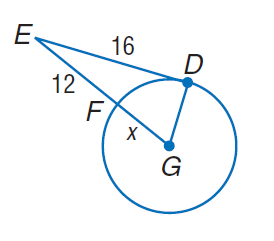

In [3]:
ds = W.unit("geometry3k_test")
diagram_id = W.pick_diagram(ds)
d = ds.diagrams[diagram_id]
print(diagram_id, "| points:", sorted(d.points), "| marked relations:", [(r.type, r.args) for r in d.asserted])
W.original_image(ds, d)

## 3. Every query: the model, the ruler and the marks

One row per applicable decision. `p` is the model's probability and `model` its decision at the
threshold; `verifier` is the ruler's verdict from the coordinates, with the margin in units of the
tolerance (at most 1 means the relation holds); `marked` says whether the human annotation asserts it;
`p_eval` is the probability the stored square-padded evaluation recorded for the same query, so the
two columns should agree.

In [4]:
results = W.read_diagram(model, ds, diagram_id, thresholds, device, run=run)
table = W.decision_table(results)
table

,query,primitives,relation,p,threshold,model,verifier,margin_over_tol,marked,p_eval,agrees_with_verifier,highlight_attention
0,0,DE DG,parallel,0.000,0.85,False,False,15.50,False,0.000,True,0.79
1,0,DE DG,perpendicular,0.996,0.90,True,True,0.05,False,0.996,True,0.79
2,0,DE DG,equal_length,0.000,0.70,False,False,5.78,False,0.000,True,0.79
3,1,DE EF,parallel,0.000,0.85,False,False,6.01,False,0.000,True,0.72
4,1,DE EF,perpendicular,0.000,0.90,False,False,14.28,False,0.000,True,0.72
5,1,DE EF,equal_length,0.009,0.70,False,False,3.36,False,0.010,True,0.72
6,2,DE EG,parallel,0.000,0.85,False,False,6.03,False,0.000,True,0.70
7,2,DE EG,perpendicular,0.000,0.90,False,False,14.27,False,0.000,True,0.70
8,2,DE EG,equal_length,0.914,0.70,True,True,0.78,False,0.915,True,0.70
9,3,DE FG,parallel,0.000,0.85,False,False,6.07,False,0.000,True,0.82


In [5]:
print(f"{len(results)} queries, {len(table)} decisions")
print(f"model agrees with the verifier on {table.agrees_with_verifier.mean():.0%} of them")
print(f"largest difference from the stored evaluation: {(table.p - table.p_eval).abs().max():.3f}")
unmarked = table[table.verifier & ~table.marked]
print(f"true in the drawing but unmarked: {len(unmarked)}; the model says yes to {unmarked.model.sum()} of them")
table[table.model != table.verifier.astype(bool)]

22 queries, 36 decisions
model agrees with the verifier on 94% of them
largest difference from the stored evaluation: 0.007
true in the drawing but unmarked: 4; the model says yes to 2 of them


,query,primitives,relation,p,threshold,model,verifier,margin_over_tol,marked,p_eval,agrees_with_verifier,highlight_attention
20,6,DG FG,equal_length,0.562,0.70,False,True,0.04,False,0.569,False,0.72
25,11,DE circle0,tangent,0.912,0.95,False,True,0.04,False,0.911,False,0.78


## 4. What the model saw

For a query, three panels: the diagram, the model's input with the query highlighted in green, and the
last-layer CLS attention over that input (patch tokens only; the register tokens are dropped). First a
relation the drawing keeps but nobody marked, which the model reads correctly.

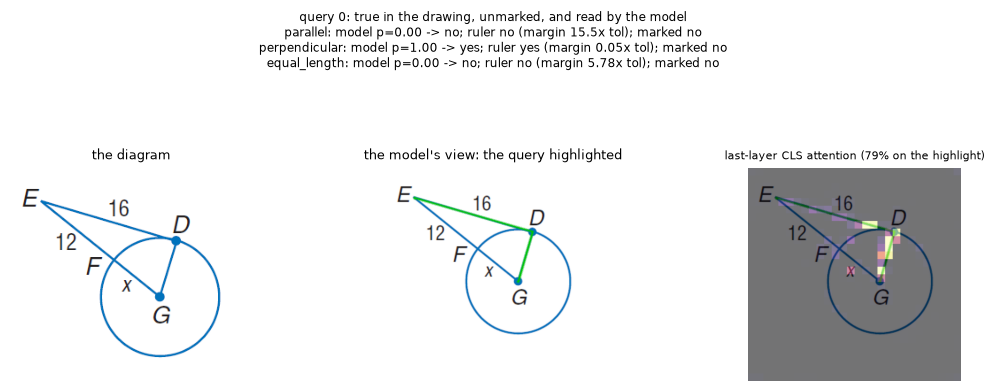

In [6]:
k = next(i for i, r in enumerate(results)
         if any(x["verifier"] and not x["marked"] and x["model"] for x in r["decisions"]))
W.show_query(results[k], ds, f"query {k}: true in the drawing, unmarked, and read by the model");

Then a decision where the model and the ruler disagree. The margin column says whether the ruler's
verdict was clear-cut or decided close to its tolerance.

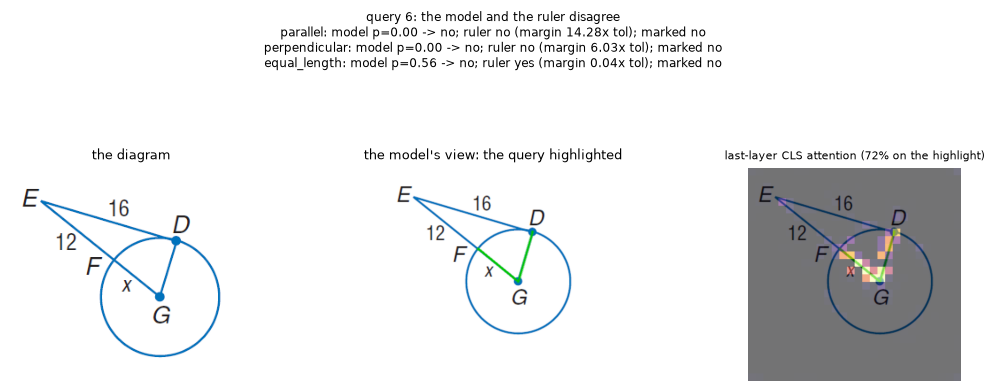

In [7]:
k = next(i for i, r in enumerate(results) if any(x["model"] != bool(x["verifier"]) for x in r["decisions"]))
W.show_query(results[k], ds, f"query {k}: the model and the ruler disagree");

## 5. Where to go from here

* Pass another `diagram_id` (any id in `ds.rows`) to `read_diagram`, or another unit to `W.unit`
  (`pgdp5k_heldout`, `synth_extrap`).
* `results[k]["maps"]["rollout"]` holds the attention-rollout map for the same query.
* The statistics over many queries (where attention falls: highlight, other ink, blank paper, padding)
  are produced by `python -m analysis.attention_maps`; the numbers are in the report.